# Mini-symposium and evidence-based synthesis

How can we communicate a useful scientific result without claiming more than the evidence supports?

Fall 2024.


# Audit a claim before presenting it
Predict which tests detect a constant positive bias and which detect a mean-only field. All examples below are synthetic candidates around known heat truth, not trained-model or patient results.

In [1]:
import numpy as np
from demo import run,correlation
from operator_bench import metrics
from IPython.display import SVG,display
y=np.array([1.,3.,5.])
p=y+2
print("Correlation:",correlation(p,y))
print("Value errors:",metrics(p,y))

Correlation: 0.9999999999999998
Value errors: {'rms': 2.0, 'relative_l2': 0.5855400437691199, 'max_error': 2.0, 'mean_error': 2.0}


## Implement one field error
Complete the RMS expression. The guided vectors here differ from the assigned problem. Predict why a shift remains visible in this statistic.

In [2]:
def my_rms(prediction,reference):
    difference=np.asarray(prediction)-np.asarray(reference)
    result=None  # TODO: square root of the mean squared difference
    return result
trial=my_rms([3.,5.,7.],[1.,3.,5.])
if trial is None:
    print("Complete the RMS expression, then rerun.")
else:
    np.testing.assert_allclose(trial,2.,rtol=0,atol=1e-14)
    print("Guided RMS check passed:",trial)

Complete the RMS expression, then rerun.


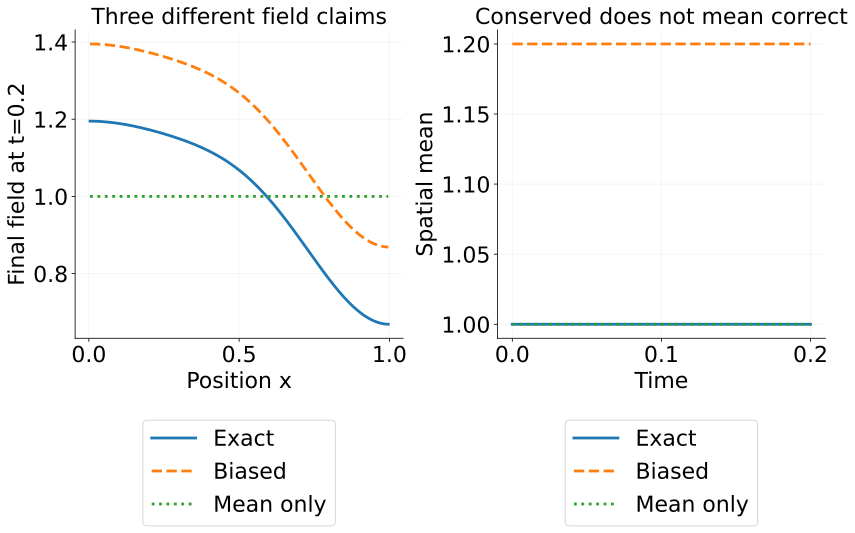

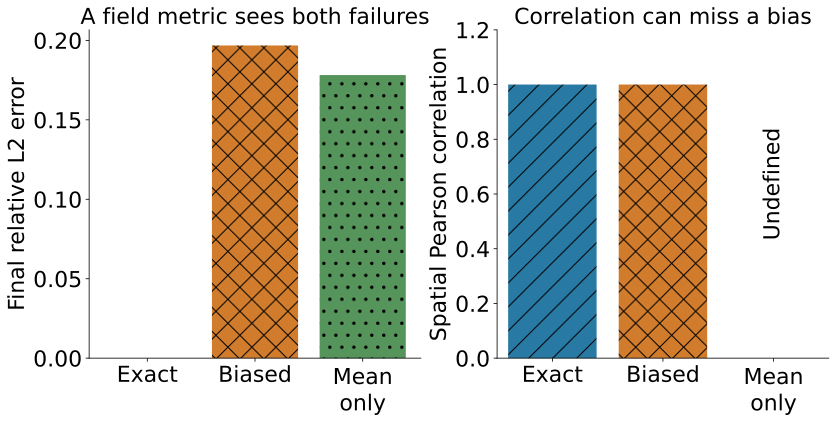

Exact {'rms': 0.0, 'relative_l2': 0.0, 'max_error': 0.0, 'mean_error': 0.0} correlation 0.9999999999999999
Biased {'rms': 0.19999999999999996, 'relative_l2': 0.19680001590086993, 'max_error': 0.20000000000000007, 'mean_error': 0.2} correlation 1.0
Mean only {'rms': 0.18106504687287464, 'relative_l2': 0.17816802051836747, 'max_error': 0.3312386581075246, 'mean_error': 2.1260476625696596e-17} correlation None


In [3]:
results=run()
display(SVG(filename="field-and-moment.svg"))
display(SVG(filename="evidence-audit.svg"))
for row in results["candidates"]:
    print(row["candidate"],row["final_errors"],"correlation",row["final_spatial_correlation"])

## Modify the counterexample
Predict the correlation and value error after multiplying the reference by1.5. Then compare with a constant field equal to its mean. Explain any undefined metric.

In [4]:
for label,candidate in [("Rescaled",1.5*y),("Mean only",np.full_like(y,y.mean()))]:
    print(label,"correlation",correlation(candidate,y),"errors",metrics(candidate,y))

Rescaled correlation 0.9999999999999998 errors {'rms': 1.707825127659933, 'relative_l2': 0.5, 'max_error': 2.5, 'mean_error': 1.5}
Mean only correlation None errors {'rms': 1.632993161855452, 'relative_l2': 0.47809144373375745, 'max_error': 2.0, 'mean_error': 0.0}


Prepare a short presentation outline with model identity, one supported result, a matched reference, an explicit limitation and a feasible next test. Write one actionable review question for another group. Do not infer clinical validation from this synthetic audit.